# Single Asset Analyzer
Γράψε ticker στο κελί 2 και τρέξε από πάνω προς τα κάτω.
Δοκιμές, επισκευές και έλεγχοι ζουν στον φάκελο `dev/`, όχι εδώ.

In [1]:
# ── SETUP ────────────────────────────────────────────────────────────────
# DEV_MODE = True μόνο όταν μόλις άλλαξες κώδικα στο quality_scores/
# (ξαναφορτώνει τα modules χωρίς restart). Για κανονική χρήση: False.
DEV_MODE = True

import warnings; warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt

if DEV_MODE:
    import importlib
    import db as _db; importlib.reload(_db)
    import fundamentals as _f; importlib.reload(_f)
    from quality_scores import line_items as _li; importlib.reload(_li)
    from quality_scores import piotroski as _pi; importlib.reload(_pi)
    from quality_scores import piotroski_plots as _pp; importlib.reload(_pp)
    from valuation import pe as _pe; importlib.reload(_pe)
    from valuation import pe_plots as _pep; importlib.reload(_pep)

from db import get_engine
from quality_scores.piotroski import piotroski_f_score, print_report, piotroski_history
from quality_scores.piotroski_plots import plot_report, plot_history
from valuation.pe import pe_history, print_pe_summary, print_peer_coverage, print_band_summary, print_decomposition
from valuation.pe_plots import plot_pe, plot_pe_bands, plot_decomposition
from valuation.pe import debug_ttm

eng = get_engine()
print(f"✅ Έτοιμο | DEV_MODE={'ON' if DEV_MODE else 'OFF'}")


✅ Έτοιμο | DEV_MODE=ON


In [3]:
TICKER = "MSFT"
AS_OF = None  # π.χ. "2022-06-30" για "ό,τι ήξερε η αγορά τότε"


In [2]:
from valuation.pe import debug_ttm
for t in ["APH", "ACN", "NFLX", "JNJ", "CDNS"]:
    debug_ttm(t, eng, since="2024-06-01")
    print("\n" + "═" * 70 + "\n")

── APH: γραμμές EPS στη βάση από 2024-06-01 ──
form_type period_start period_end  days filed_date  value
     10-Q   2024-04-01 2024-06-30    90 2024-07-26   0.41
     10-Q   2024-07-01 2024-09-30    91 2024-10-25   0.48
     10-K   2024-01-01 2024-12-31   365 2025-02-07   1.92
     10-Q   2025-01-01 2025-03-31    89 2025-04-25   0.58
     10-Q   2025-04-01 2025-06-30    90 2025-07-25   0.86
     10-Q   2025-07-01 2025-09-30    91 2025-10-24   0.97
     10-K   2025-01-01 2025-12-31   364 2026-02-11   3.34
     10-Q   2026-01-01 2026-03-31    89 2026-05-01   0.72
     10-Q   2026-04-01 2026-06-30    90 2026-07-31   1.37
  (σύνολο στη βάση: 69 γραμμές, τελευταίο filed 2026-07-31)

── Παραγωγή Q4 ──
  FY 2022-01-01→2022-12-31: ✓ Q4 = 3.06 − 2.24 = 0.82
  FY 2023-01-01→2023-12-31: ✓ Q4 = 3.11 − 2.28 = 0.83
  FY 2024-01-01→2024-12-31: ✓ Q4 = 1.92 − 1.76 = 0.16
  FY 2025-01-01→2025-12-31: ✓ Q4 = 3.34 − 2.41 = 0.93

── Τελευταία TTM ──
period_end  available  eps_ttm
2025-09-30 2025-10-25     

In [4]:
import pandas as pd
from sqlalchemy import text

sql = text("""
    SELECT f.ticker, f.fiscal_year, f.fiscal_period,
           f.period_start, f.period_end, f.filed_date, f.value
    FROM fundamentals f
    JOIN metric_lookup m     ON m.id  = f.metric_id
    JOIN form_type_lookup ft ON ft.id = f.form_type_id
    WHERE m.name = 'EarningsPerShareDiluted' AND ft.name = '10-Q'
      AND f.ticker = ANY(:t) AND f.fiscal_year BETWEEN 2024 AND 2026
    ORDER BY f.ticker, f.fiscal_year, f.fiscal_period
""")
with eng.connect() as c:
    print(pd.read_sql(sql, c, params={"t": ["ACN", "APH", "CDNS"]}).to_string(index=False))

# Πόσο μεγάλο είναι το πρόβλημα σε όλη τη βάση (όλα τα metrics, όχι μόνο EPS):
sql2 = text("""
    SELECT COUNT(*) AS groups, COUNT(DISTINCT ticker) AS tickers
    FROM (
        SELECT ticker, metric_id, form_type_id, period_end
        FROM fundamentals
        WHERE period_start IS NOT NULL
        GROUP BY ticker, metric_id, form_type_id, period_end
        HAVING COUNT(DISTINCT fiscal_year) > 1
    ) x
""")
with eng.connect() as c:
    print(c.execute(sql2).fetchone())

ticker  fiscal_year fiscal_period period_start period_end filed_date  value
   ACN         2024            Q1   2023-09-01 2023-11-30 2023-12-19   3.10
   ACN         2024            Q2   2023-12-01 2024-02-29 2024-03-21   2.63
   ACN         2024            Q3   2024-03-01 2024-05-31 2024-06-20   3.04
   ACN         2025            Q1   2024-09-01 2024-11-30 2024-12-19   3.59
   ACN         2025            Q2   2023-12-01 2024-02-29 2025-03-20   2.63
   ACN         2025            Q3   2025-03-01 2025-05-31 2025-06-20   3.49
   ACN         2026            Q1   2025-09-01 2025-11-30 2025-12-18   3.54
   ACN         2026            Q2   2025-12-01 2026-02-28 2026-03-19   2.93
   ACN         2026            Q3   2026-03-01 2026-05-31 2026-06-18   3.80
   APH         2024            Q1   2024-01-01 2024-03-31 2024-04-26   0.87
   APH         2024            Q2   2024-04-01 2024-06-30 2024-07-26   0.41
   APH         2024            Q3   2024-07-01 2024-09-30 2024-10-25   0.48
   APH      

# PIOTROSKI F-SCORE
## ΤΙ ΕΙΝΑΙ:
9 ερωτήσεις "ναι/όχι" για την οικονομική υγεία μιας εταιρείας,
συγκρίνοντας την τελευταία χρονιά (φέτος) με την προηγούμενη (πέρσι).
Κάθε "ναι" = 1 πόντος. Γενικά: 7–9 = υγιής, 0–3 = αδύναμη.
Αν λείπει κάποιο νούμερο, η ερώτηση ΔΕΝ μετράει ως αποτυχία — γράφεται
"δεν αξιολογήθηκε" και το score δίνεται ως "πόντοι / όσα ελέγχθηκαν".

## - ΚΕΡΔΟΦΟΡΙΑ -

## 1. Κερδοφόρα (ROA > 0)
    Έβγαλε κέρδος φέτος;  ROA = κέρδη / assets στην ΑΡΧΗ της χρονιάς.
    Παράδειγμα: κέρδη 10, assets αρχής 100 → ROA 10% → ΝΑΙ.

## 2. Θετικές ταμειακές ροές (CFO > 0)
    Μπήκαν πραγματικά χρήματα στο ταμείο από τη λειτουργία της εταιρείας;
    τα κέρδη μπορεί να είναι "στα χαρτιά" — το ταμείο δεν ξεγελιέται εύκολα.

## 3. ROA βελτιώθηκε
    Η κερδοφορία ανά ευρώ assets ανέβηκε σε σχέση με πέρσι;
    Παράδειγμα: πέρσι 9%, φέτος 11% → ΝΑΙ.
    Γιατί assets ΑΡΧΗΣ χρονιάς: αν η εταιρεία αγόρασε άλλη τον Δεκέμβριο
    και τα assets διπλασιάστηκαν, αυτά δεν δούλεψαν όλη τη χρονιά. Με τα
    assets του τέλους θα φαινόταν ψευδώς ότι η κερδοφορία έπεσε στο μισό.

## 4. Ταμείο > λογιστικά κέρδη
    Οι ταμειακές ροές είναι μεγαλύτερες από τα κέρδη;
    Παράδειγμα: κέρδη 10, ταμείο 14 → ΝΑΙ (τα κέρδη "στηρίζονται" σε
    μετρητά). Αν ήταν κέρδη 10, ταμείο 3 → ΟΧΙ: μεγάλο μέρος των κερδών
    είναι απαιτήσεις/λογιστικές εγγραφές, κλασικό προειδοποιητικό σημάδι.

## - ΧΡΕΟΣ & ΡΕΥΣΤΟΤΗΤΑ - 

## 5. Λιγότερο χρέος
    Μακροπρόθεσμο χρέος / ΜΕΣΟ ΟΡΟ assets έπεσε σε σχέση με πέρσι;
    Παράδειγμα: πέρσι 25%, φέτος 20% → ΝΑΙ.
    Συγκρίνεται πάντα το ΙΔΙΟ μέτρο και τις δύο χρονιές: αν πέρσι
    δηλώθηκαν δύο κομμάτια χρέους (30 + 70) και φέτος μόνο το ένα (70),
    συγκρίνουμε 70 με 70 — όχι 100 με 70, που θα έδειχνε ψεύτικη μείωση.

## 6. Καλύτερη ρευστότητα (current ratio)
    Current ratio = ό,τι γίνεται μετρητά μέσα σε 1 χρόνο / ό,τι πρέπει
    να πληρωθεί μέσα σε 1 χρόνο. Ανέβηκε σε σχέση με πέρσι;
    Παράδειγμα: πέρσι 1.40x, φέτος 1.25x → ΟΧΙ.

## 7. Όχι νέες μετοχές
    Ο αριθμός μετοχών έμεινε ίδιος ή μειώθηκε; Νέες μετοχές = η πίτα
    μοιράζεται σε περισσότερους (dilution). Buybacks = ΝΑΙ.
    Αν ο αριθμός άλλαξε κατά ~x2, x4, x10 κτλ. είναι πιθανότατα split
    (π.χ. AAPL 4:1 το 2020: 4.4B → 17B μετοχές) → "δεν αξιολογήθηκε",
    γιατί το split δεν είναι dilution.

## - ΑΠΟΔΟΤΙΚΟΤΗΤΑ - 

## 8. Μεικτό περιθώριο ↑
    Από κάθε 100€ πωλήσεων, πόσα μένουν μετά το κόστος του προϊόντος;
    Παράδειγμα: πέρσι 37.8€, φέτος 38.2€ → ΝΑΙ (καλύτερη τιμολόγηση ή
    φθηνότερη παραγωγή).

## 9. Αποδοτικότητα assets ↑ (asset turnover)
    Πόσες πωλήσεις βγάζει κάθε 1€ assets (αρχής χρονιάς);
    Παράδειγμα: πέρσι 0.71€, φέτος 0.81€ → ΝΑΙ (τα ίδια assets "δουλεύουν" περισσότερο).


── Piotroski F-Score: NFLX ──────────────────
   FY2025 vs FY2024  (filed 2026-01-23)
   Score: 6 / 8

   Κερδοφορία
   [PASS]  Κερδοφόρα (ROA > 0)          φέτος 20.5%
   [PASS]  Θετικές ταμειακές ροές       φέτος $10.15B
   [PASS]  ROA βελτιώθηκε               πέρσι 17.9%  φέτος 20.5%
   [FAIL]  Ταμείο > λογιστικά κέρδη     κέρδη $10.98B  ταμείο $10.15B

   Χρέος & ρευστότητα
   [PASS]  Λιγότερο χρέος               πέρσι 27.0%  φέτος 24.7%
            ↳ χρέος: μόνο μακροπρόθεσμο (ίδιο μέτρο και στα δύο έτη)
   [FAIL]  Καλύτερη ρευστότητα          πέρσι 1.22x  φέτος 1.19x
   [N/A ]  Όχι νέες μετοχές             πέρσι 427.8M  φέτος 4.22B
            ↳ πιθανό split 10:1 — η σύγκριση δεν έχει νόημα

   Αποδοτικότητα
   [PASS]  Μεικτό περιθώριο ↑           πέρσι 46.1%  φέτος 48.5%
            ↳ μεικτό κέρδος = έσοδα − κόστος πωληθέντων
   [PASS]  Αποδοτικότητα assets ↑       πέρσι 0.80x  φέτος 0.84x


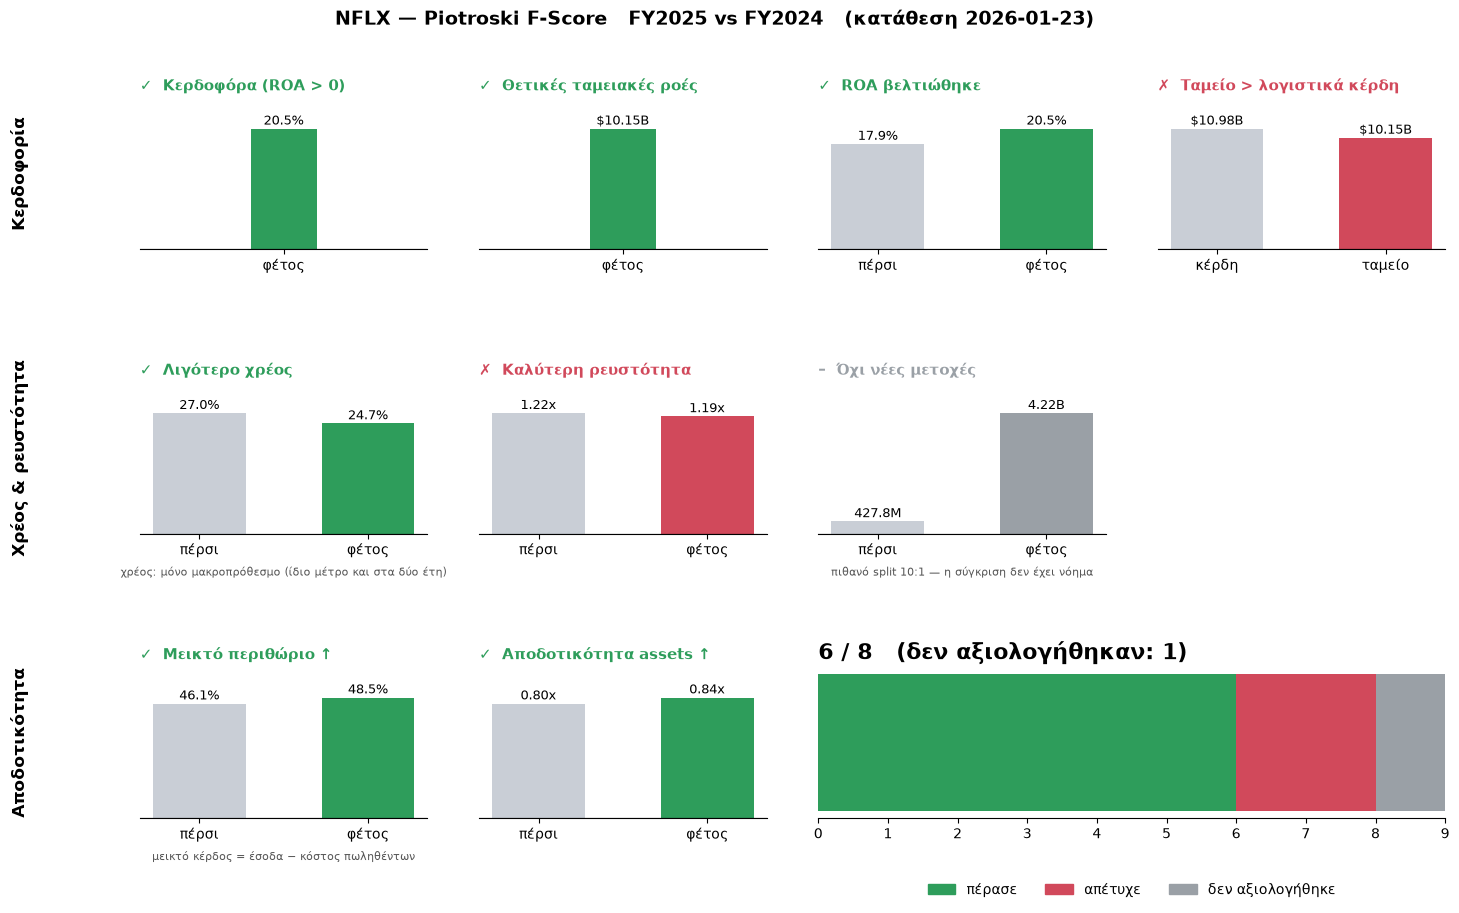

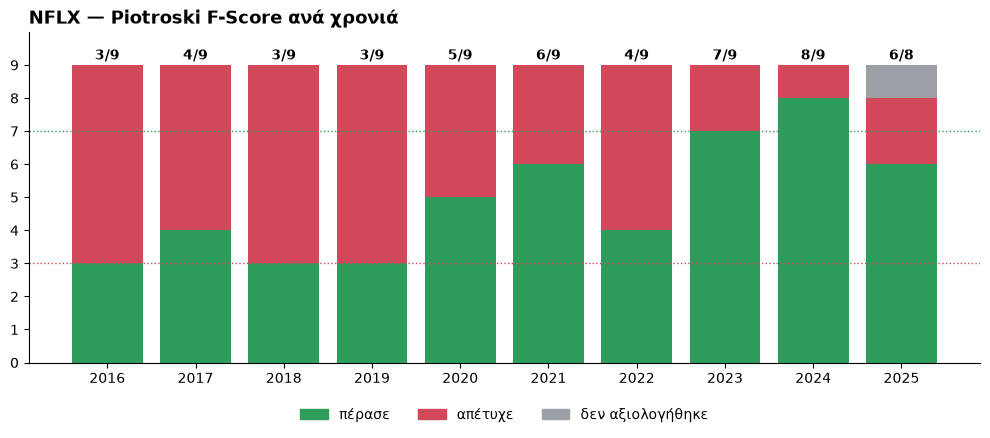

In [19]:
# ── PIOTROSKI F-SCORE ────────────────────────────────────────────────────
res = piotroski_f_score(TICKER, eng, as_of=AS_OF)
print_report(res)
plot_report(res)
plt.show()

plot_history(piotroski_history(TICKER, eng, n_years=10), TICKER)
plt.show()


# P/E — ΦΘΗΝΗ Η ΑΚΡΙΒΗ;
## ΤΙ ΕΙΝΑΙ:
P/E = τιμή μετοχής / κέρδη ανά μετοχή των τελευταίων 12 μηνών (EPS TTM).
Δείχνει πόσα πληρώνεις για κάθε 1 ετήσιου κέρδους.
Παράδειγμα: τιμή 100, EPS TTM 5 → P/E 20 → "πληρώνεις 20 χρόνια κερδών".

## Πώς διαβάζεται το διάγραμμα
    Πάνω: η τιμή. Κάτω: το P/E της μετοχής (μπλε) μαζί με:
    - τη διακεκομμένη μπλε = ο "συνήθης" P/E της ίδιας στην περίοδο
      (μπλε γραμμή πάνω της → πιο ακριβή από ό,τι συνήθως),
    - την πορτοκαλί = διάμεσος P/E του κλάδου,
    - την πορτοκαλί ζώνη = εκεί βρίσκεται η "μεσαία" μισή του κλάδου.
    Γκρι φόντο = η εταιρεία είχε ζημιές → το P/E δεν ορίζεται.

## Προσοχή στην ερμηνεία
    Χαμηλό P/E ≠ αυτόματα ευκαιρία: μπορεί η αγορά να περιμένει πτώση κερδών.
    Υψηλό P/E ≠ αυτόματα φούσκα: μπορεί να περιμένει γρήγορη ανάπτυξη.
    Το P/E λέει "πόσο ακριβά πληρώνεις", όχι "αν αξίζει".


⬇️  Τιμές + EPS για NFLX και 30 peers (Communication Services)...
── Κάλυψη peers: sector «Communication Services» (30 εταιρείες) ──
    2  EPS αλλά χωρίς συνεχόμενα τρίμηνα (TTM)    EA, PSKY
    5  ok                                         DIS, FOX, FOXA, NWS, NWSA
    1  ζημιές (EPS ≤ 0)                           TTWO
   20  παλιό EPS (> 270 μέρες)                    APP, CHTR, CMCSA, ECHO, GOOG, GOOGL, +14
    2  χωρίς EPS στη βάση                         UCL, WB
── NFLX — P/E (TTM) ── 2026-10-05 ──
  P/E: —  (δεν υπάρχει πρόσφατο EPS)


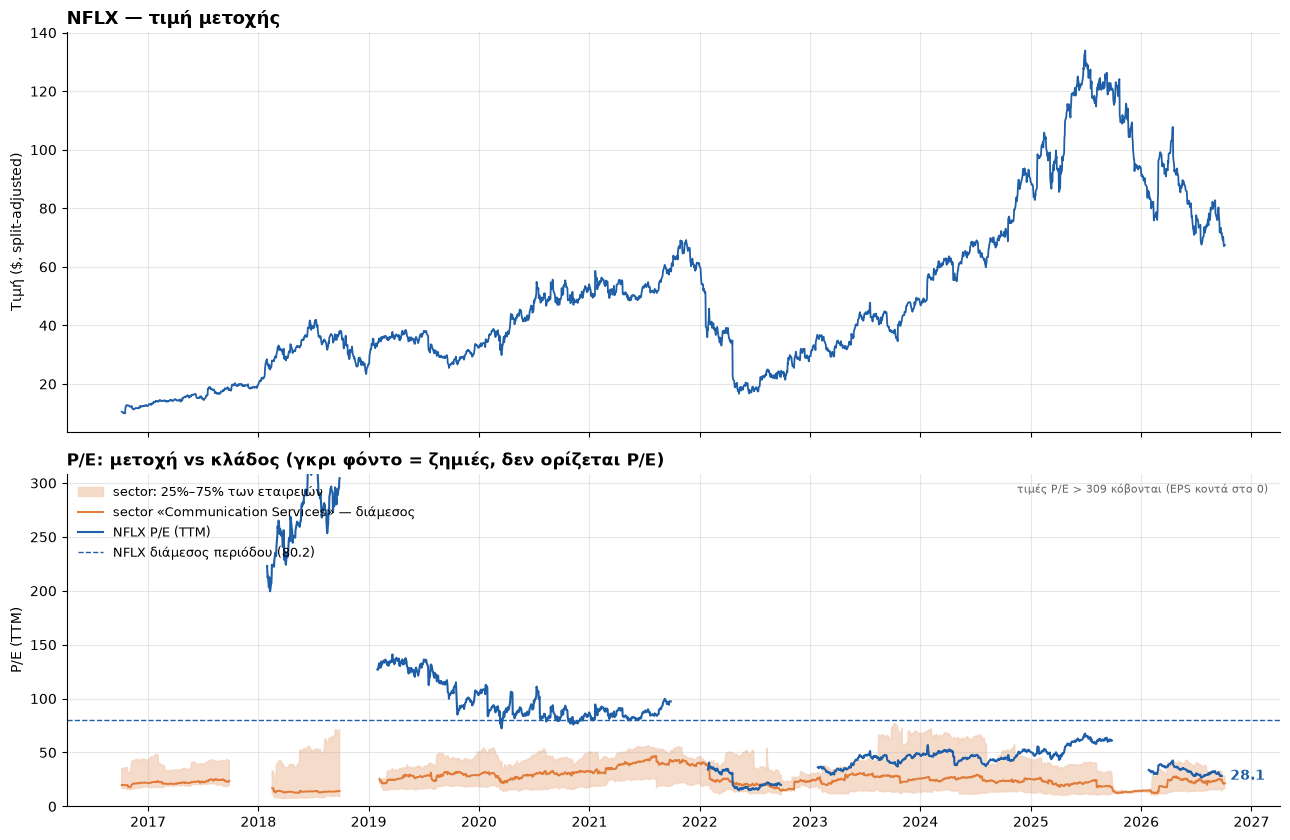

In [20]:
# ── P/E: ΤΙΜΗ & ΑΠΟΤΙΜΗΣΗ ─────────────────────────────────────────────────
PEER_GROUP = "sector"   # ή "industry" (στενότερη ομάδα, λιγότερες εταιρείες)
PE_YEARS = 10

pe = pe_history(TICKER, eng, years=PE_YEARS, as_of=AS_OF, peer_group=PEER_GROUP)
print_peer_coverage(pe)
print_pe_summary(pe)
plot_pe(pe)
plt.show()


# P/E BANDS — ΠΟΥ ΘΑ ΗΤΑΝ Η ΤΙΜΗ ΣΤΟ "ΣΥΝΗΘΙΣΜΕΝΟ" P/E;
## ΤΙ ΕΙΝΑΙ:
Τιμή στο P/E X = EPS TTM × X. Αν EPS = 5 και ο συνήθης P/E της μετοχής είναι 20, η "λογική" τιμή είναι 100.
Η πράσινη ζώνη = P/E ανάμεσα στο 25% και 75% των ημερών της ίδιας της μετοχής.

    Μπλε (τιμή) κάτω από τη ζώνη → φθηνή σε σχέση με το δικό της παρελθόν
    Μπλε μέσα στη ζώνη           → κανονική αποτίμηση
    Μπλε πάνω από τη ζώνη        → ακριβή σε σχέση με το δικό της παρελθόν

Προσοχή: τα όρια υπολογίζονται από ΟΛΟ το διάστημα (και το μέλλον κάθε ημέρας) — περιγραφικό διάγραμμα, όχι σήμα για backtest.


P/E bands: μη διαθέσιμα (ζημιές ή έλλειψη EPS).


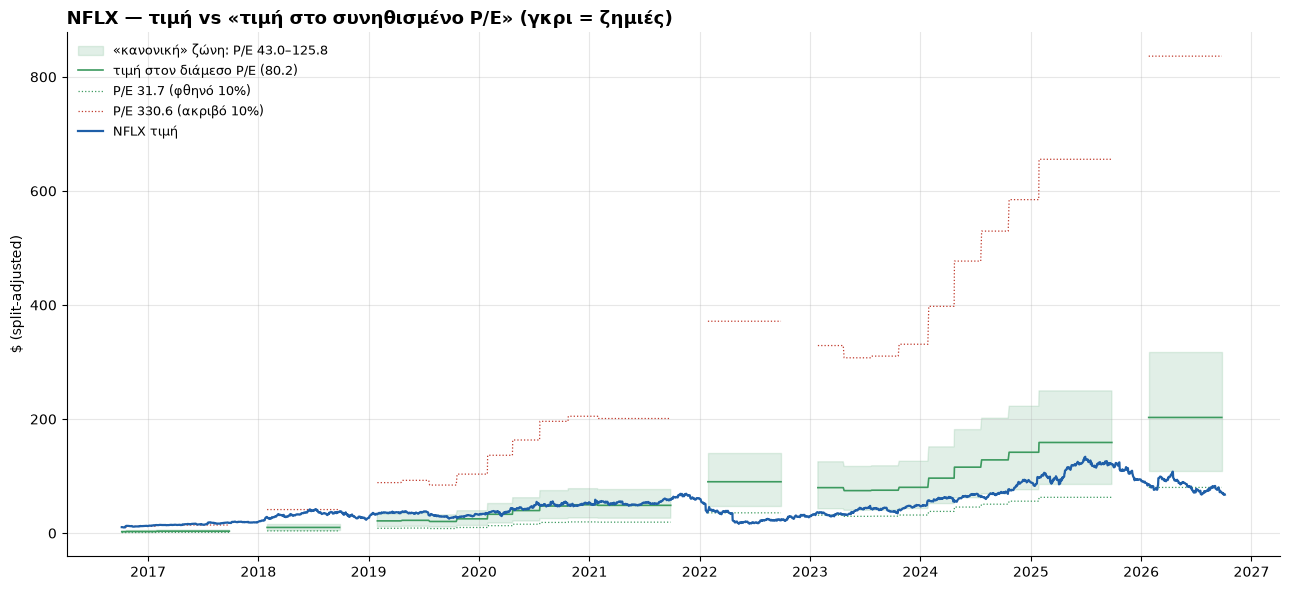

In [21]:
# ── P/E BANDS ──────────────────────────────────────────────────────────────
print_band_summary(pe)
plot_pe_bands(pe)
plt.show()


# ΑΠΟ ΠΟΥ ΗΡΘΕ Η ΑΠΟΔΟΣΗ — ΚΕΡΔΗ Η P/E;
## ΤΙ ΕΙΝΑΙ:
Τιμή = EPS × P/E, άρα μεταβολή τιμής = μεταβολή κερδών × μεταβολή P/E.
Παράδειγμα: τιμή 50$→100$ (×2) = κέρδη 2.5→4 (×1.6) × P/E 20→25 (×1.25).

    Άνοδος από κέρδη → η εταιρεία έγινε πραγματικά καλύτερη (πιο "υγιής" άνοδος)
    Άνοδος από P/E   → η αγορά απλώς πληρώνει ακριβότερα· μπορεί να γυρίσει πίσω

Χωρίς μερίσματα. Έτη με EPS κοντά στο 0 εμφανίζονται με "—" (ο διαχωρισμός δεν έχει νόημα).


── NFLX — από πού ήρθε η απόδοση (10/2016 → 09/2026, χωρίς μερίσματα) ──
  Τιμή ×6.77 = κέρδη ×80.14  ×  P/E ×0.08   (P/E 332.8 → 28.1)
  +577% συνολικά = +1323% από κέρδη -746% από αλλαγή P/E
  ⚠️  P/E > 80 στην αρχή ή στο τέλος (EPS κοντά στο 0): το σύνολο παραμορφώνεται.
            Έτος  Τιμή %  από κέρδη %  από P/E %
2016 (από 06/10)    17.8         16.0        1.9
            2020    67.1         89.3      -22.2
            2024    83.1         78.1        5.0


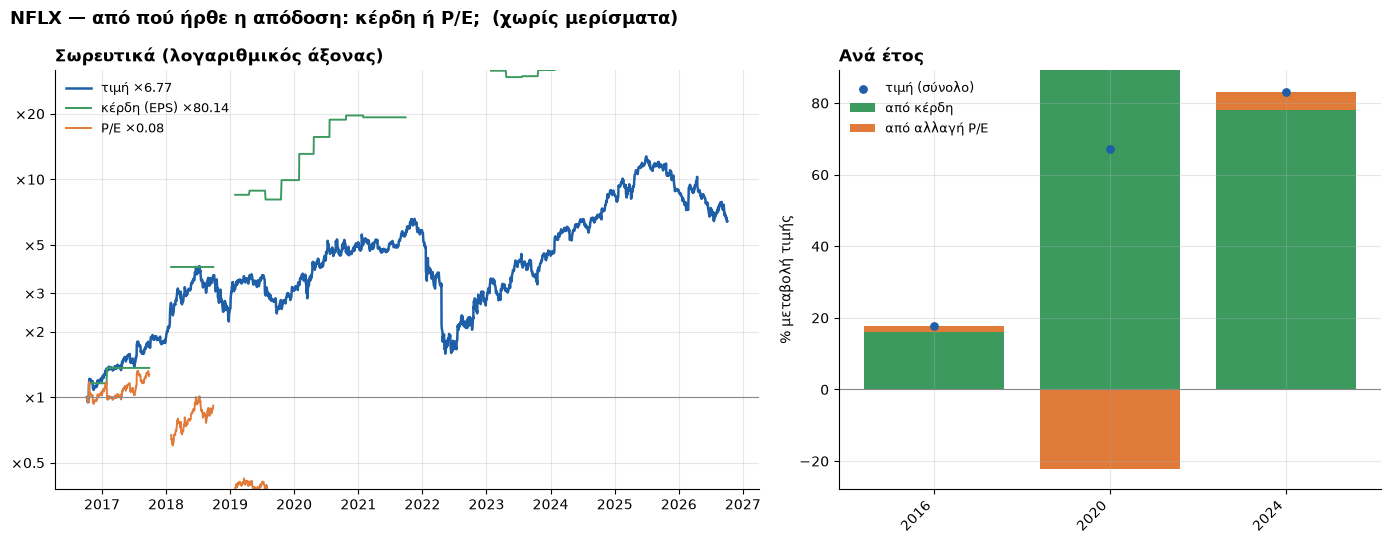

In [22]:
# ── ΑΝΑΛΥΣΗ ΑΠΟΔΟΣΗΣ ──────────────────────────────────────────────────────
print_decomposition(pe)
plot_decomposition(pe)
plt.show()


## Βασικές μετρικές
*(Βήμα 2 — έρχεται με το `metrics.py`)*

In [4]:
TICKER = "MSFT"
pe = pe_history(TICKER, eng, years=10, peer_group="sector")
print_peer_coverage(pe)
print_pe_summary(pe)

print_report(piotroski_f_score(TICKER, eng))

⬇️  Τιμές + EPS για MSFT και 102 peers (Technology)...
── Κάλυψη peers: sector «Technology» (102 εταιρείες) ──
   86  ok                                         AAPL, ACN, ADBE, ADI, ADP, ADSK, +80
    8  ζημιές (EPS ≤ 0)                           CRWD, INTC, LITE, S, SEDG, TRMB, +2
    7  παλιό EPS (> 270 μέρες)                    CRM, GDDY, PARA, Q, RAL, USBC, +1
    1  σταμάτησε να διαπραγματεύεται              QRVO
── MSFT — P/E (TTM) ── 2026-10-09 ──
  Τιμή 535.07 / EPS TTM 17.95 = P/E 29.8
  Διάμεσος P/E της ίδιας (2016–): 33.1  → το σημερινό είναι υψηλότερο από το 34% των ημερών
  Διάμεσος P/E sector «Technology» (86 εταιρείες): 34.5  → φθηνότερη κατά 14%
── Piotroski F-Score: MSFT ──────────────────
   FY2026 vs FY2025  (filed 2026-07-29)
   Score: 6 / 9

   Κερδοφορία
   [PASS]  Κερδοφόρα (ROA > 0)          φέτος 21.6%
   [PASS]  Θετικές ταμειακές ροές       φέτος $182.94B
   [PASS]  ROA βελτιώθηκε               πέρσι 19.9%  φέτος 21.6%
   [PASS]  Ταμείο > λογιστικά κέρδη     